<a href="https://colab.research.google.com/github/yashvityagi/fetal-ultrasound-segmentation/blob/main/DataAnalysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
!pip install unrar
!unrar x /content/Datasets.rar

print("Contents of the main 'Datasets' directory after 2extraction:")
!ls -R /content/Datasets

Streaming output truncated to the last 5000 lines.
Extracting  Datasets/test/malignant/489_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/491_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/494_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/496_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/499_2HC_Annotation.png                77%  OK 
Extracting  Datasets/test/malignant/49_2HC.png                            77%  OK 
Extracting  Datasets/test/malignant/501_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/503_HC_Annotation.png                 77%  OK 
Extracting  Datasets/test/malignant/504_HC.png                            77%  OK 
Extracting  Datasets/test/malignant/507_HC.png                            77%  OK 
Extracting  Datasets/test/mal

In [ ]:
!ls -R /content/Datasets/Datasets/

/content/Datasets/Datasets/:
benign	malignant  normal

/content/Datasets/Datasets/benign:
 100_HC.png    18_HC.png     277_HC.png    63_HC.png
 101_HC.png    190_HC.png    278_2HC.png   64_2HC.png
 102_2HC.png   191_4HC.png   279_HC.png    65_2HC.png
 10_2HC.png    192_2HC.png   280_HC.png    66_HC.png
 103_HC.png    193_HC.png    281_HC.png    67_HC.png
 104_HC.png    194_2HC.png   282_2HC.png   68_HC.png
 105_3HC.png   195_HC.png    283_HC.png    69_HC.png
 106_HC.png    196_HC.png    284_HC.png    6_HC.png
 107_3HC.png   197_HC.png    285_HC.png    70_2HC.png
 108_HC.png    198_HC.png    286_HC.png    71_HC.png
 109_HC.png    199_HC.png    287_4HC.png   72_HC.png
 110_HC.png    19_HC.png     288_HC.png    7_2HC.png
 111_HC.png    1_HC.png      289_HC.png    73_2HC.png
 112_2HC.png   200_HC.png    28_HC.png	   74_2HC.png
 113_HC.png    201_HC.png    290_HC.png    75_HC.png
 114_HC.png    202_2HC.png   291_HC.png    76_HC.png
 115_HC.png    203_HC.png    292_2HC.png   77_HC.png
 116_H

In [ ]:
import os
import glob
import pandas as pd

# Define the root path to the extracted dataset based on the initial 'unrar' output
root_dir = '/content/Datasets'

# Lists to store file paths and labels
image_paths = []
labels = []

# Iterate through the main subdirectories (e.g., 'test', 'validation')
for subset_name in os.listdir(root_dir):
    subset_path = os.path.join(root_dir, subset_name)
    if os.path.isdir(subset_path):
        # Iterate through each category (benign, malignant, normal) within the subset
        for category_name in os.listdir(subset_path):
            category_path = os.path.join(subset_path, category_name)
            if os.path.isdir(category_path):
                # Get all image files (assuming .png format)
                for image_file in glob.glob(os.path.join(category_path, '*.png')):
                    image_paths.append(image_file)
                    labels.append(category_name) # The label is 'benign', 'malignant', or 'normal'

# Create a DataFrame
df_images = pd.DataFrame({"image_path": image_paths, "label": labels})

# Display the first few rows and value counts
print("First 5 rows of the image DataFrame:")
display(df_images.head())

print("\nDistribution of labels:")
display(df_images['label'].value_counts())

First 5 rows of the image DataFrame:


,image_path,label
0,/content/Datasets/test/normal/176_2HC.png,normal
1,/content/Datasets/test/normal/89_HC.png,normal
2,/content/Datasets/test/normal/308_HC.png,normal
3,/content/Datasets/test/normal/31_HC.png,normal
4,/content/Datasets/test/normal/303_HC.png,normal



Distribution of labels:


,count
label,
malignant,4507
benign,776
normal,750


In [ ]:
import os

dataset_path = "/content/Datasets/Datasets/"

total_images = 0

for root, dirs, files in os.walk(dataset_path):
    total_images += len([f for f in files if f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.tif', '.tiff'))])

print("Total Images:", total_images)

Total Images: 2964


In [ ]:
print(df_images.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6033 entries, 0 to 6032
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image_path  6033 non-null   object
 1   label       6033 non-null   object
dtypes: object(2)
memory usage: 94.4+ KB
None


In [ ]:
# Get a statistical summary
df_images.describe()

,image_path,label
count,6033,6033
unique,6033,3
top,/content/Datasets/train/benign/277_HC.png,malignant
freq,1,4507


In [ ]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

def display_samples(base_path, num_samples=4):
    classes = os.listdir(base_path)
    # Filter out hidden files like .ipynb_checkpoints if they exist
    classes = [c for c in classes if not c.startswith('.')]

    # Handle cases where there might be no valid classes
    if not classes:
        print(f"No image classes found in {base_path}")
        return

    fig, axes = plt.subplots(len(classes), num_samples, figsize=(12, len(classes) * 3))

    for idx, cls in enumerate(classes):
        cls_path = os.path.join(base_path, cls)
        # Ensure cls_path is a directory before listing its contents
        if not os.path.isdir(cls_path):
            print(f"Skipping {cls_path} as it is not a directory.")
            # If it's not a directory, we need to assign an empty row to axes to prevent errors
            # or handle it differently if it's the only class
            if len(classes) > 1:
                for i in range(num_samples):
                    axes[idx, i].axis('off') # Turn off axes for this row
            else:
                for i in range(num_samples):
                    axes[i].axis('off')
            continue

        images = os.listdir(cls_path)
        # Filter for actual image files to prevent errors with non-image files
        image_files = [img for img in images if img.lower().endswith(('.png', '.jpg', '.jpeg', '.gif', '.bmp'))]

        if not image_files:
            print(f"No image files found in {cls_path}")
            if len(classes) > 1:
                for i in range(num_samples):
                    axes[idx, i].axis('off')
            else:
                for i in range(num_samples):
                    axes[i].axis('off')
            continue

        sampled_images = random.sample(image_files, min(num_samples, len(image_files)))

        for i, img_name in enumerate(sampled_images):
            img_path = os.path.join(cls_path, img_name)
            try:
                img = Image.open(img_path)

                # If there's only one class, axes is a 1D array
                ax = axes[idx, i] if len(classes) > 1 else axes[i]
                ax.imshow(img)
                ax.set_title(f"{cls}\n{img.size}")
                ax.axis('off')
            except Exception as e:
                print(f"Error loading image {img_path}: {e}")
                ax = axes[idx, i] if len(classes) > 1 else axes[i]
                ax.set_title("Error")
                ax.axis('off')

    plt.tight_layout()
    plt.show()


Displaying sample images from the 'test' dataset:


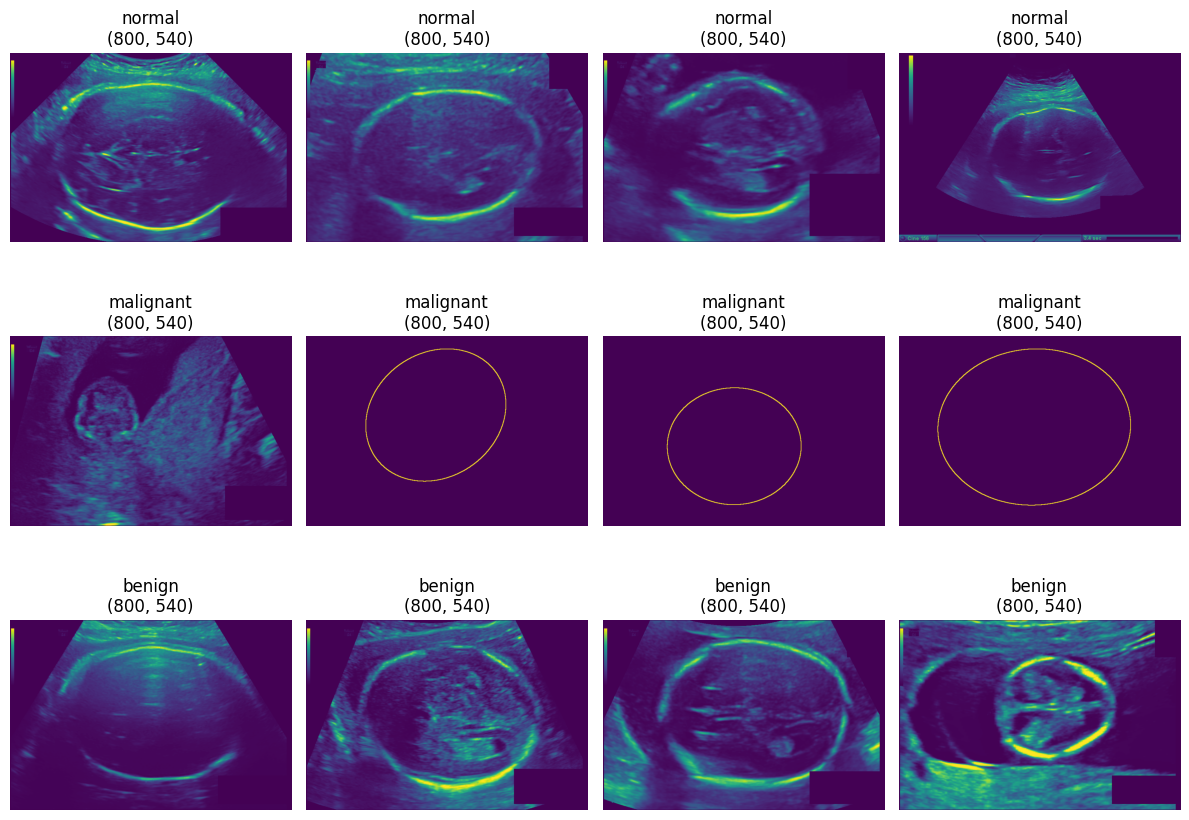


Displaying sample images from the 'train' dataset:


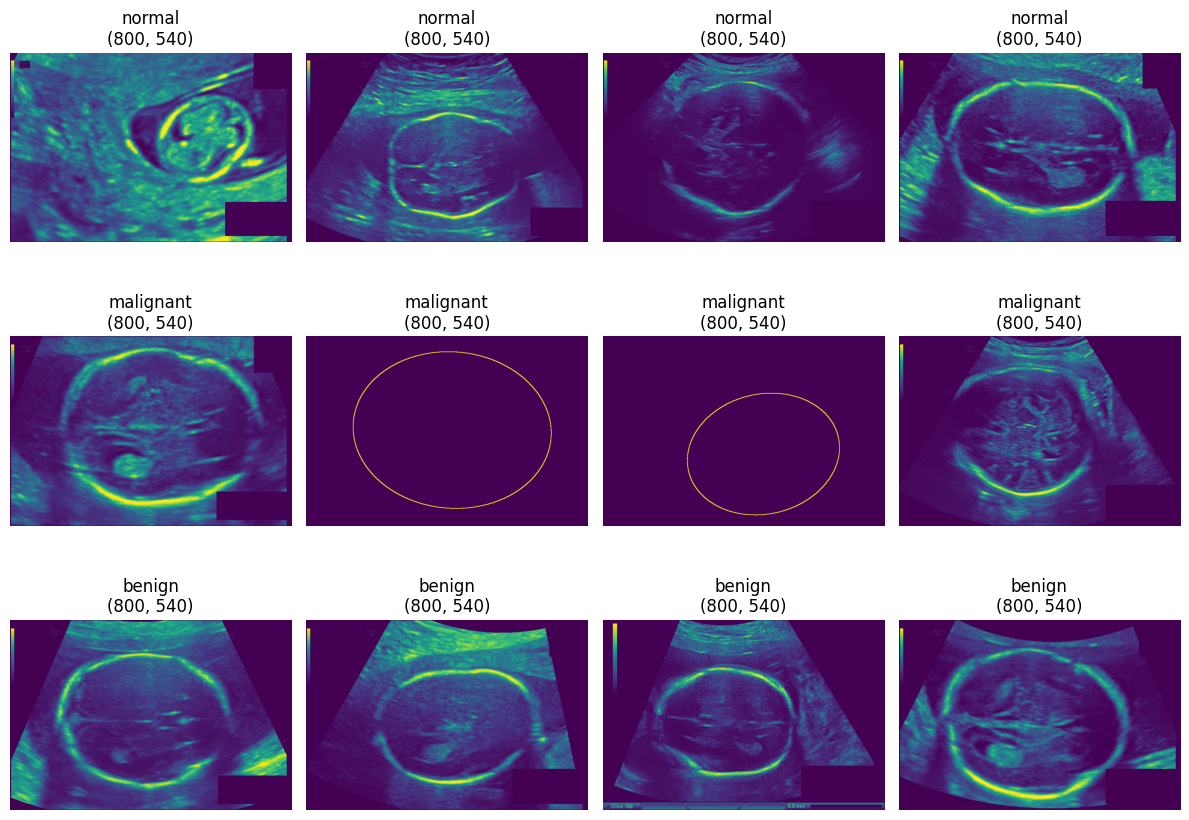

In [ ]:
print("Displaying sample images from the 'test' dataset:")
display_samples('/content/Datasets/test')
plt.show() # Explicitly call show after the first set of plots

print("\nDisplaying sample images from the 'train' dataset:")
display_samples('/content/Datasets/train')
plt.show() # Explicitly call show after the second set of plots


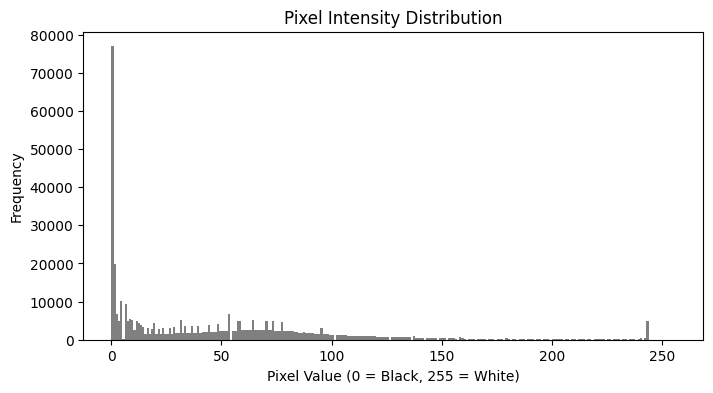

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt # Import matplotlib

# Load an image in grayscale to check brightness distribution
# Using an image path from df_images
# Ensure df_images is available and has at least one image path
if not df_images.empty:
    sample_image_path = df_images['image_path'].iloc[0]
    sample_img = cv2.imread(sample_image_path, cv2.IMREAD_GRAYSCALE)
else:
    print("df_images is empty. Cannot load a sample image.")
    sample_img = None

if sample_img is not None:
    plt.figure(figsize=(8, 4))
    plt.hist(sample_img.ravel(), bins=256, range=[0, 256], color='gray')
    plt.title('Pixel Intensity Distribution')
    plt.xlabel('Pixel Value (0 = Black, 255 = White)')
    plt.ylabel('Frequency')
    plt.show()
else:
    print("Failed to load sample image for pixel intensity distribution.")


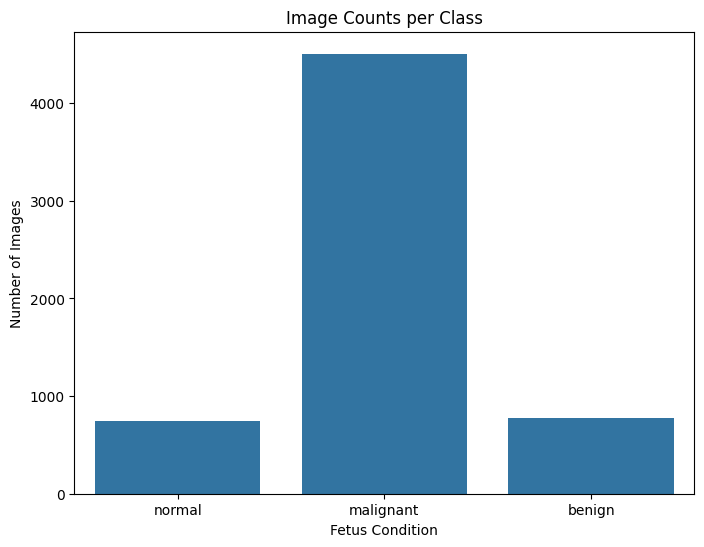

In [ ]:
import seaborn as sns
plt.figure(figsize=(8, 6))
sns.countplot(x='label', data=df_images)
plt.title('Image Counts per Class')
plt.xlabel('Fetus Condition')
plt.ylabel('Number of Images')
plt.show()

In [ ]:
DATASET_PATH = "/content/Datasets/"

train_dir = os.path.join(DATASET_PATH, "train")
val_dir   = os.path.join(DATASET_PATH, "validation")
test_dir  = os.path.join(DATASET_PATH, "test")

print("Train dir:", train_dir)
print("Validation dir:", val_dir)
print("Test dir:", test_dir)
print("Classes trouvées:", sorted(os.listdir(train_dir)))

Train dir: /content/Datasets/train
Validation dir: /content/Datasets/validation
Test dir: /content/Datasets/test
Classes trouvées: ['benign', 'malignant', 'normal']


In [ ]:
def build_dataframe(split_dir):
    rows = []
    for class_name in sorted(os.listdir(split_dir)):
        class_path = os.path.join(split_dir, class_name)
        if not os.path.isdir(class_path):
            continue

        for fname in os.listdir(class_path):
            if fname.lower().endswith((".png", ".jpg", ".jpeg")):
                rows.append({
                    "filepath": os.path.join(class_path, fname),
                    "label": class_name
                })
    return pd.DataFrame(rows)

train_df = build_dataframe(train_dir)
val_df   = build_dataframe(val_dir)
test_df  = build_dataframe(test_dir)

print("\nDistribution train :")
print(train_df["label"].value_counts())

print("\nDistribution validation :")
print(val_df["label"].value_counts())

print("\nDistribution test :")
print(test_df["label"].value_counts())


Distribution train :
label
malignant    1443
normal        242
benign        241
Name: count, dtype: int64

Distribution validation :
label
malignant    255
benign        43
normal        43
Name: count, dtype: int64

Distribution test :
label
malignant    300
benign        51
normal        50
Name: count, dtype: int64


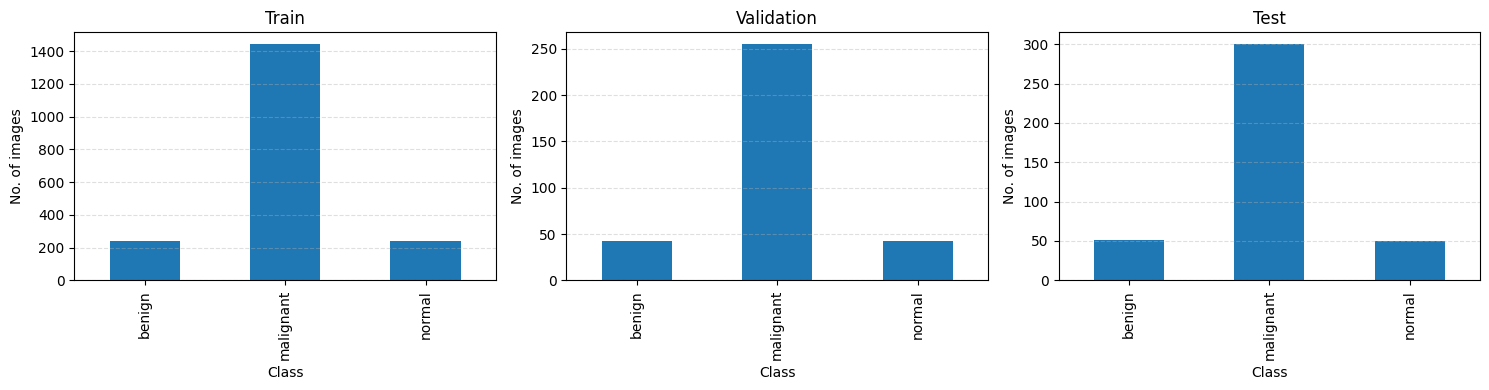

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

train_df["label"].value_counts().sort_index().plot(kind="bar", ax=axes[0], title="Train")
val_df["label"].value_counts().sort_index().plot(kind="bar", ax=axes[1], title="Validation")
test_df["label"].value_counts().sort_index().plot(kind="bar", ax=axes[2], title="Test")

for ax in axes:
    ax.set_xlabel("Class")
    ax.set_ylabel("No. of images")
    ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [ ]:
def find_corrupted_images(df):
    corrupted = []
    for path in df["filepath"]:
        try:
            img = cv2.imread(path)
            if img is None:
                corrupted.append(path)
        except Exception:
            corrupted.append(path)
    return corrupted

corrupted_train = find_corrupted_images(train_df)
corrupted_val   = find_corrupted_images(val_df)
corrupted_test  = find_corrupted_images(test_df)

print("Corrupted train:", len(corrupted_train))
print("Corrupted validation:", len(corrupted_val))
print("Corrupted test:", len(corrupted_test))

Corrupted train: 0
Corrupted validation: 0
Corrupted test: 0
